# Oxygen Optode Pipeline: Aanderaa

This notebook is the workspace for writing the code that processes dissolved oxygen measured on glider optodes, which will be integrated into the toolbox being developed at NOC within the GLIDERS - RISC project. Only working with Aanderaa optodes for now. A separate notebook will be created for other optodes (e.g., SeaBird). 

Start: 20251031

By: Elise Droste (elise.droste@noc.ac.uk)



***
# Resources

The processing steps are based on previous work in the DO optode community, as well as how it is done for BGC Argo. This is a list of links to consulted works and code: 

<b>Manuscripts</b>
- Bittig et al. (2018): https://www.frontiersin.org/journals/marine-science/articles/10.3389/fmars.2017.00429/full 
- Bittig & Körtzinger (2017)


<b>SOPs</b>
- Ocean Gliders SOPs: https://oceangliderscommunity.github.io/Oxygen_SOP/README.html
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/ \ https://archimer.ifremer.fr/doc/00348/45915/56281.pdf
- IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual: https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf : Woo, L.M. and Gourcuff, C. (2023). Delayed Mode QA/QC Best Practice Manual Version 3.1 Integrated Marine Observing System. DOI: 10.26198/5c997b5fdc9bd (https://dx.doi.org/10.26198/5c997b5fdc9bd)

  DOI: https://dx.doi.org/10.26198/5c997b5fdc9bd
- Thierry et al. (2025), Argo Quality Control Manual: https://archimer.ifremer.fr/doc/00354/46542/
- Thierry et al. (2025a), Processing Argo Pxygen data at the DAC level: https://dx.doi.org/10.13155/39795 

<b>Code - Public</b>
- Ocean Gliders O2 SOP GitHub: https://github.com/OceanGlidersCommunity/Oxygen_SOP
- UEA Seagldier Toolbox: https://bitbucket.org/bastienqueste/uea-seaglider-toolbox/src/toolbox/
- Bittig et al. (2016): https://archimer.ifremer.fr/doc/00348/45915/

<b>Code - Private</b>
- Filipa Carvalho: matlab files. 
- Charlotte: TBA

***
# Processing roadmap

A visualisation of the oxygen optode processing pipeline can be found here: 

https://www.figma.com/board/7bYMOu1zaj6fzAU1Ar2YQ8/Glider_DO_Optode_Pipeline?node-id=0-1&p=f&t=vkOw6Ba9V9yyuACe-0 

***
# Packages

## conda environment

<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
Add notes on yml file and add link on how to install it.
</div>

## Python packages

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import datetime
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from IPython.core.interactiveshell import InteractiveShell 
InteractiveShell.ast_node_interactivity = "all" # allow multiple outputs from 1 cell


## Modules

<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
Once functions have been tested, move all into a Class and save as module.
</div>

***
# Organisation

## Import calibration sheet

Calibration coefficients are saved in a subfolder, called _calibration_sheets_, which contains the data in py files that can be imported here. 

Add calibration data from the manufacturer in the appropriate calibration sheet, saved in dir _calibration_sheets_. 

In [2]:
from calibration_sheets import calibration_sheet_aa4831 as cal_sheet_aa

In [3]:
cal_sheet_aa.SVUFoilCoef0

0.00267915

## Import settings

Set settings in _optode_pipeline_settings.py_, found in _settings_. 

In [4]:
from settings import optode_pipeline_settings

In [5]:
optode_pipeline_settings.Pcoef1

0.1

In [6]:
optode_pipeline_settings.uncal_phase

'BPHASE'

***
# General functions

Check if instance is array-like. 

In [7]:
def is_array_like(obj):
    return isinstance(obj, (np.ndarray, xr.DataArray, pd.Series, list, tuple))

Run data through a low-pass filter. 

In [8]:
from scipy.signal import butter, filtfilt

In [9]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

***
# Data

Code is tested on data from the BioCarbon project. The data imported here is the output of the toolbox pipeline in the format in which it will be passed onto the optode pipeline. 

IDs of gliders: 
- Churchill 647
- Doombar 648


Data imported here are data previously exported from the prototype toolbox pipeline in August 2025. 

In [18]:
%%bash

cd ../RISC_DO_Optode_rawdata/profiled_data_exported
ls

exported_Churchill_647_R.nc
exported_Doombar_648_R.nc


In [11]:
fdir = "../RISC_DO_Optode_rawdata/profiled_data_exported/"
fname = "exported_Churchill_647_R.nc"
ds = xr.open_dataset(fdir + fname)

In [12]:
ds.instrument # attribute containing list of instruments on the glider

['SBE Slocum Glider Payload (GPCTD) CTD',
 'WET Labs {Sea-Bird WETLabs} ECO Puck Triplet FLBBCD-SLC scattering fluorescence sensor',
 'Oxygen optode 4831',
 'Photosynthetically Active Radiation sensor',
 'Slocum G1+G2 Glider Navigation data logger']

Instrument attribute does not contain information about the manufacturer of the optode, but we know it is Aanderaa. 

Both Churchill and Doombar have <font color=lightblue>Aanderaa 4831</font>. 



<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
Find a way to log the optode type, which is info required to make decisions along the processing tree
</div>

In [13]:
optode_pipeline_settings.optode_type = "aa4831"

Check which optode-relevant variables have values in the dataset. 

In [14]:
optode_var_list = ['PHASE',
                     'PHASE_QC',
                     'DPHASE_DOXY',
                     'MOLAR_DOXY',
                     'TPHASE_DOXY',
                     'TEMP_DOXY',
                     'OXYSAT_DOXY',
                     'DPHASE_DOXY_QC',
                     'MOLAR_DOXY_QC',
                     'TPHASE_DOXY_QC',
                     'TEMP_DOXY_QC',
                     'OXYSAT_DOXY_QC']

In [15]:
print("Optode variables with only NaNs: ")
for var_name in optode_var_list:
    print(var_name, ds[var_name].isnull().all().item())

Optode variables with only NaNs: 
PHASE True
PHASE_QC True
DPHASE_DOXY False
MOLAR_DOXY False
TPHASE_DOXY True
TEMP_DOXY False
OXYSAT_DOXY True
DPHASE_DOXY_QC False
MOLAR_DOXY_QC False
TPHASE_DOXY_QC True
TEMP_DOXY_QC False
OXYSAT_DOXY_QC True


We have data:
- <b>DPHASE</b>: calibrated phase measurement. Unit = degrees.
- <b>MOLAR_DOXY</b>: DO (dissolved oxygen concentration at zero pressure and in fresh water or at a reference salinity). Unit = umol L-1. These values are calculated by the instrument using manufacturer settings, but does not include a pressure correction on the phase shift. <font color=pink> We re-calculate this ourselves. </font>
- <b>TEMP_DOXY</b>: Optode temperature measurements. Unit = degrees Celsius.

QC flags of variables with non-nan values are only [0, nan]: 

In [19]:
np.unique(ds["DPHASE_DOXY_QC"])
np.unique(ds["MOLAR_DOXY_QC"])
np.unique(ds["TEMP_DOXY_QC"])

array([ 0., nan], dtype=float32)

array([ 0., nan], dtype=float32)

array([ 0., nan], dtype=float32)

***
# Find starting phase shift [READY]

## Find uncalibrated phase shift (UNCAL_PHASE)

Aanderaa optodes measure a blue light and a red light excitation, BPHASE and RPHASE, respectively. 

<img src=markdown_pngs/optode_IMOS.png width="500"/>
[Optode optical design (Aanderaa, 2007; copied from Woo & Gourcurr, 2023 - IMOS)]


The uncalibrated phase (UNCAL_PHASE, i.e., uncalibrated for temperature) is the difference between the excitation measured from the blue and red light: 

$$UNCAL\_PHASE = BPHASE - RPHASE$$

However, RPHASE is often not used, so 

$$UNCAL\_PHASE = BPHASE$$

Thierry et al. (2025a): For 3830 optodes, UNCAL_Phase = BPhase. For 4330 optodes, Uncalibrated phase =  TCPhase, so: 

$$UNCAL\_PHASE = TCPHASE$$

<font color=pink> We prefer UNCAL_PHASE, BPHASE, or TCPHASE in OG1 file. </font>

So, we need either BPHASE or UNCAL_PHASE to start with. 

Dataset might contain optode phase shift data at different "stages" of calculation, e.g., BPHASE, UNCAL_PHASE, DPHASE_DOXY, etc. 
Here run through data variables within the dataset and try to find the available uncalibrated optode phase shift data in this order: 
1. BPHASE (uncalibrated)
2. UNCAL_PHASE (uncalibrated)
3. TCPHASE (uncalibrated)


<font color=pink> Side note: PHASE variable in dataset is the behaviour of the glider at sea, it has nothing to do with the optode. </font>  

Continue pipeline with the <i>lowest level phase shift</i> available. 

Next, a pressure correction will be applied to the uncalibrated phase shift (UNCAL_PHASE_Pcorr), followed by converting it to a calibrated phase shift (DPHASE_DOXY). 



<div class="alert alert-block alert-warning">
<b>To do: </b> 
    
- Add what the other variables are that we might find of other Aandereaa optodes, e.g. TPHASE and CALPHASE.
- Consider using a varying variable to accommodate different names for uncalibrated and calibrated phase shifts.
</div>

In [20]:
def find_uncalibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings): 
    
    uncal_phase_found = ""
    raw_phase_names = ["BPHASE", "UNCAL_PHASE", "TCPHASE"]

    for phase_optode in raw_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                if phase_optode == "BPHASE": # if BPHASE, calculate CAL_PHASE
                    if "UNCAL_PHASE" in ds.data_vars: # replace existing UNCAL_PHASE
                        ds["UNCAL_PHASE"].values = ds[phase_optode].values # replaces values of array only, but keeps attributes of original array
                        print("UNCAL_PHASE determined from, ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase = phase_optode # set the uncalibrated phase shift variable 
                    else: # Create new UNCAL_PHASE variable based on BPHASE
                        ds["UNCAL_PHASE"] = ds[phase_optode] # this keeps the attributes of the original PHASE array
                        # ds.assign(UNCAL_PHASE = ds.BPHASE) # this does not keep the attributes of the original BPHASE array
                        print("UNCAL_PHASE determined from, ", phase_optode, ".")
                        uncal_phase_found = phase_optode
                        optode_pipeline_settings.uncal_phase = phase_optode # set the uncalibrated phase shift variable 
                    break # get out of loop
                    
                elif phase_optode == "UNCAL_PHASE": 
                    print("UNCAL_PHASE found and contains values. Continue with UNCAL_PHASE. ")
                    uncal_phase_found = phase_optode
                    optode_pipeline_settings.uncal_phase = phase_optode # set the uncalibrated phase shift variable 
                    break # get out of loop
    
                elif phase_optode == "TCPHASE": 
                    print("TCPHASE found and contains values. Continue with TCPHASE. ")
                    uncal_phase_found = phase_optode
                    optode_pipeline_settings.uncal_phase = phase_optode # set the uncalibrated phase shift variable 
                    break # get out of loop
    
                else:
                    uncal_phase_found = None

        else: 
            uncal_phase_found = None
        
    if uncal_phase_found == None: 
        print("No uncalibrated phase shift found. ")

    return uncal_phase_found
                   
    

<div class="alert alert-block alert-success">
STEP: Check if BPHASE or UNCAL_PHASE or TCPHASE exist in dataset:
</div>

In [21]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_uncalibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings)

No uncalibrated phase shift found. 


## Find calibrated phase shift (CALPHASE)

1. DPHASE (calibrated) --> <font color=orange> If this is the most raw data available for phase shift, then the pressure correction to phase shift cannot be applied. </font>
3. CALPHASE (calibrated)

In [22]:
def find_calibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings): 
    cal_phase_found = ""
    cal_phase_names = ["DPHASE_DOXY", "CALPHASE"]

    for phase_optode in cal_phase_names: 
        if phase_optode in all_optode_phases_list: # if phase exists in the dataset
            if bool(ds[phase_optode].isnull().all()): # check phase type contains only NaNs
                print(phase_optode, " exists but contains only NaNs.")
            else: # data exist! 
                print(phase_optode, " found. ")
                cal_phase_found = phase_optode
                optode_pipeline_settings.cal_phase = phase_optode # set the uncalibrated phase shift variable 
                break # get out of loop
        else: 
            print("No calibrated phase shifts found. ")
            cal_phase_found = None
    
    if cal_phase_found == None: 
        print("No calibrated phase shift found. ")

    return cal_phase_found

<div class="alert alert-block alert-success">
STEP: Check if DPHASE or CALPHASE exist in dataset:
</div>

In [23]:
all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

find_calibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings)

DPHASE_DOXY  found. 


'DPHASE_DOXY'

## Find phase shift (combined)

In [24]:
def find_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings): 
    all_optode_phases_list = [v for v in ds.data_vars if ("PHASE" in v) & ("QC" not in v) ] # List all variable names containing "PHASE", exclude QC arrays
    all_optode_phases_list = [v for v in all_optode_phases_list if v not in ("PHASE")] # Remove the PHASE variable (= glider behaviour)

    if len(all_optode_phases_list) == 0: # If nothing has been found 
        print("No variables names containing PHASE found. Check naming conventions. ")

    else: 
        # Check if uncalibrated phase shift data are present
        uncal_phase_found = find_uncalibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings)
        
        if isinstance(uncal_phase_found, str): # if  uncalibrated phase shift data are present
            print("Uncalibrated phase shift found! Continue pipeline with ", uncal_phase_found, ". Next step: pressure correction. ")
            print("Settings updated for uncal_phase: ", optode_pipeline_settings.uncal_phase)
            
        else: # if uncalibrated phase shift data are not present, check for calibrated phase shift data
            cal_phase_found = find_calibrated_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings)
            
            if isinstance(cal_phase_found, str): 
                print("No uncalibrated phase shifts found, but found calibrated phase shift: ", cal_phase_found, ". Continue with this but skip pressure correction on phase shift.")
                print("Settings updated for cal_phase: ", optode_pipeline_settings.cal_phase)
            else: 
                print("No uncalibrated or calibrated phase shifts found. Check data variables. ")

    print("Check: uncalibrated phase shift used for next steps is ", optode_pipeline_settings.uncal_phase, ".")
    print("Check: calibrated phase shift used for next steps is ", optode_pipeline_settings.cal_phase, ".")


<div class="alert alert-block alert-success">
STEP: Check if/which uncalibrated or calibrated phase shift data exist in dataset:
</div>

In [25]:
find_phase_optode(ds, all_optode_phases_list, optode_pipeline_settings)


No uncalibrated phase shift found. 
DPHASE_DOXY  found. 
No uncalibrated phase shifts found, but found calibrated phase shift:  DPHASE_DOXY . Continue with this but skip pressure correction on phase shift.
Settings updated for cal_phase:  DPHASE_DOXY
Check: uncalibrated phase shift used for next steps is  BPHASE .
Check: calibrated phase shift used for next steps is  DPHASE_DOXY .


***
# Geometrically align phase shift to CTD data [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input:  </b>
    
- geo_time_lag

<b>Optional input:  </b>

- distance between optode and CTD on glider
- glider dive rate
- glider pitch
</div>



We require CTD data for the next processing steps. However, since the CTD and optode sensors are not located in the same space on the glider, there's a time lag between the two. So we need to shift CTD data to align with the optode in space and in time, i.e., geometrically. 

<img src=markdown_pngs/glider_geo_shift.png width="500"/>
[Glider orientation during descent (copied from Woo & Gourcurr, 2023 - IMOS)]


The geometic lag time ($\tau$) to travel the distance between the Optode and the CTD recorder is calculated as:

$$\tau = \frac{d}{v}$$

where ($d$) is the distance between the sensors (default of 90 cm) and ($v$) is the glider's velocity of travel, which is given by:

$$v = \frac{r}{\sin(\theta)}$$

$r$ is the dive rate (m/s) and ($\theta$) is the glider pitch (degrees).


This can be done in two ways: 

1. <b>Use a default geometric time lag from Woo et al. (2023).</b>

   a) Shift CTD data, incl. depth, in time to align with optode measurements.

   b) Interpolate shifted CTD data incl. depth for optode measurement times.

   c) Make sure to add shifted depth and interpolated CTD data to original CTD variables.
   
2. <b>Use calculated the geometric time lag based on distance between optode and CTD on the glider, glider dive rate, and glider pitch. </B>

   a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.

   b) Filter geometric time lag through low pass filter (separately for up and down casts).

   c) Shift CTD data incl. depth accordingly.

   d) Interpolate shifted CTD data incl. depth for optode measurement times. 

   e) Make sure to add shifted depth and interpolated CTD data to the original CTD variables. 



<div class="alert alert-block alert-warning">
Have not implemented this yet!! 

- Discuss with Dan: where in the pipeline shall we implement this? "Temporary variables?"
</div>



In [215]:
def calc_mean_per_cast(ds, var): # TO DO  - need to know how to determine up and down cast separately 
    """
    Calculate the mean of a given variable per cast. 

    ARGS:
        var : string
            Name of variable in the dataset. 

    RETURN: 
        var_mean_per_cast = array-like 
            Mean of variable per cast. 

    Note: 
        PROFILE_NUMBER -1 and 0 are excluded!
    """ 

    # Calculate mean time per cast
    mean_time_per_cast = ds["TIME"].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # PROFILE_NUMBER -1 and 0 are excluded! 

    # Calculate mean of variable per cast
    mean_var_per_cast = ds[var].groupby(ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0)).mean() # TO DO: replace profile_number with cast (up/down)

    # Assign mean time to mean variable 
    mean_var_per_cast = mean_var_per_cast.assign_coords(TIME=mean_time_per_cast)

    # Sort by time: necessary? 
    # mean_var_per_cast = mean_var_per_cast.sortby("TIME")


    return mean_var_per_cast
    

In [16]:
def lowpass_filter(data, cutoff, fs, order=3):
    """
    Apply Butterworth filter to smoothen dataset. It is a filtering method that does not distort the amplitude of low-frequency signals. 
    Removes high frequency noise/"spikes", but keeps slower trends. 
    
    ARGS:
        data: array-like
            Data to be passed through lowpass filter. Make sure NaNs are excluded! Filter cannot handle NaNs. Data also needs to have even spacing. 
        cutoff: float
            Cutoff frequency (i.e., the boundary between the slow and fast variations). Unit in Hz. 
        fs: float
            sampling frequency (measurements per unit. )
        order: 
            Filter order; sharpness of transition between pass and stop bands. Higher means a sharper cutoff, but can distort edges
    """
    # Cutoff (Wn) is normalised and must be between 0 adn 1. 
    b, a = butter(N = order, Wn = cutoff / (0.5 * fs), btype="low")
    return filtfilt(b, a, data) # filtfilt applies the filter forward and backward, so there is no time lag

Testing: 

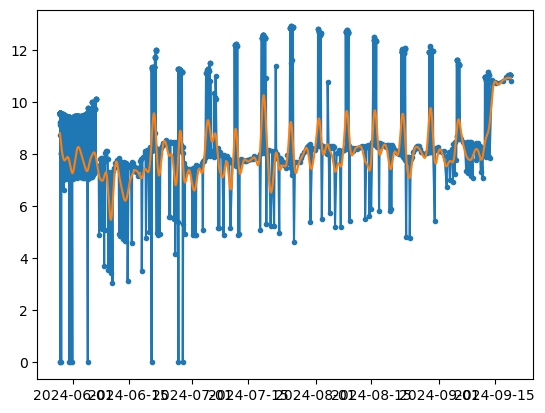

In [298]:
mean_var_per_cast = calc_mean_per_cast(ds, "TEMP")
mean_var_per_cast

mean_var_per_cast = mean_var_per_cast.swap_dims({"PROFILE_NUMBER": "TIME"})
regular = mean_var_per_cast.resample(TIME="1s").interpolate("linear")
regular_filled = regular.ffill("TIME").bfill("TIME")

fs = 1 # 1 samples per sec
cutoff = 1/(3600 * (24*2)) # remove changes faster than every 24 hours
geo_time_lag_filt = lowpass_filter(data = regular_filled, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

plt.scatter(mean_var_per_cast.TIME, mean_var_per_cast, marker = ".")
plt.plot(regular_filled.TIME, regular_filled)
plt.plot(regular_filled.TIME, geo_time_lag_filt); 

In [204]:
dt = np.diff(mean_var_per_cast["TIME"].values) / np.timedelta64(1, 'h')
print("Average time step (hours):", dt.mean(), dt.std())


Average time step (hours): 2.5045868225117087 3.411521316039896


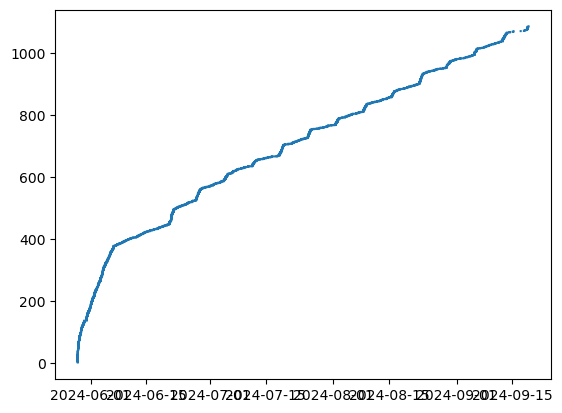

In [200]:
plt.plot(ds.TIME, ds.PROFILE_NUMBER)
plt.plot(ds.TIME.where(ds.PROFILE_NUMBER > 0), ds.PROFILE_NUMBER.where(ds.PROFILE_NUMBER > 0))

In [ ]:
def derive_geometric_time_lag(ds, dive_rate, pitch, d=None): 
    """
    Derive geometric time lag between DO optode and CTD based on dive rate and pitch, using mean dive rate and pitch per cast. 
    Following Woo & Gourcurr (2023) - IMOS. 
    
    ARGS: 
        dive_rate: array-like
            Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
        pitch: array-like
            Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. 
    RETURN: 
        geo_time_lag_filt : array-like
            Geometric time lag between OD optode and CTD (smoothed). Unit in s. 
            
    """

    # Find distance between CTD and DO optode (d)
    if isinstance(geo_time_lag, float): 
        print("Using following given distance between CTD and DO optode: ", d, " cm.")
    else: 
        d = 90 
        print("Using default distance between CTD and DO optode: ", d, " cm.")

    # Calculate the vertical velocity of travel (v)
    if (isinstance(dive_rate, float)) & (isinstance(pitch, float)): # TO DO : remove part between if and else later - not usable
        print("Using dive rate = ", dive_rate, "m s-1 and pitch = ", pitch, "deg in vertical velocity calculation. ")
    else: 
        # a) Calculate geometric time lag per up and down cast using the mean dive rate and pitch per cast.
        mean_dive_rate_per_cast = calc_mean_per_cast(ds, var = "") # Calculate mean dive rate per cast - UNKNOWN VAR - TO DO 
        mean_pitch_per_cast = calc_mean_per_cast(ds, var = "GLIDER_PITCH") # Calculate mean pitch per cast 

        mean_vert_vel_per_cast = mean_dive_rate_per_cast / np.sin(mean_pitch_per_cast) # Calculate vertical velocity per cast
        mean_geo_time_lag = d / mean_vert_vel_per_cast # Calculate geometric time lag per cast

        # Interpolate geo time lag onto regular time grid 
        mean_geo_time_lag = mean_geo_time_lag.swap_dims({"PROFILE_NUMBER": "TIME"}) # set TIME as dimension
        mean_geo_time_lag_interp = mean_geo_time_lag.resample(TIME = "1s").interpolate("linear") # interpolate onto regular grid 
        mean_geo_time_lag_interp = mean_geo_time_lag_interp.ffill("TIME").bfill("TIME") # fill NaNs at edges (filter doesn't like NaNs)

        # b) Filter geometric time lag through low pass filter (separately for up and down casts). -- TO TEST 
        fs = 1 # 1 sample per s
        cutoff = 1/(3600*12) # remove changes faster than every 12 hours - TO DO: CHECK IF THIS NEEDS ADJUSTING
        geo_time_lag_filt_interp = lowpass_filter(data = mean_geo_time_lag_interp, cutoff = cutoff, fs = fs) # pass data through low-pass filter 

        # Interpolate back onto original time frame/grid 
        geo_time_lag_filt = geo_time_lag_filt_interp.interp(TIME=geo_time_lag_filt.TIME)

    return geo_time_lag_filt

In [ ]:
def apply_geometrical_alignment(ds, geo_time_lag, ctd_vars_to_align): 
    """
    Apply linear time shift using (filtered) geometric time lag. 
    ARGS: 
        ...

    RETURN:
        Geometrically aligned variables within ctd_vars_to_align 
    """
    # When geo_time_lag is constant 

    # a) Shift CTD data, incl. depth, in time to align with optode measurements.

    # b) Interpolate shifted CTD data incl. depth for optode measurement times.

    # c) Make sure to add shifted depth and interpolated CTD data to original CTD variables.

  


    # When geo_time_lag changes (array)
    
    # c) Shift CTD data incl. depth accordingly with calculated/shifted time lag for each cast 
    
    # d) Interpolate shifted CTD data incl. depth for optode measurement times.
    
    # e) Make sure to add shifted depth and interpolated CTD data to the original CTD variables.


    return 

In [49]:
def ctd_optode_geometrical_alignment(ds, geo_time_lag, dive_rate = None, pitch = None, d = None):
    """
    Geometrical alignment
    Adjust CTD data to optode location by correcting for geometric lag (seconds). 
    Default time_lag (3.9450) from IMOS Ocean Gliders Delayed Mode QA/QC Best Practice Manual:
    https://content.aodn.org.au/Documents/IMOS/Facilities/Ocean_glider/Delayed_Mode_QAQC_Best_Practice_Manual_OceanGliders_LATEST.pdf

    Using geo_time_lag: time shift in seconds to shift CTD measurements to alight with optode position. Default = 3.9450.
    
    ARGS:
        dive_rate: array-like
            Dive rate data. Required input if time_lag == "derive". Unit in m s-1. Default = None. 
        pitch: array-like
            Pitch measurements. Required input if time_lag == "derive". Unit in deg. Default = None. 
        d: float
            Distance between the CTD and the DO optode on the glider. Unit in cm. 

    RETURN:
        shifted phase shift or CTD data? TO DO 
        
    """
    
    # Check if necessary variables are present in the dataset. -- TODO
    ctd_vars = ["TIME", "PRES", "PRAC_SALINITY", "TEMP", "DEPTH"]
    ctd_vars_to_align = []

    for ctd_var in ctd_vars: 
        if ctd_var not in ds.data_vars: 
            print(ctd_var, " not found in variable names. Geometric alignment with optode is not applied to this variable. ")
        else: 
            if bool(ds["ctd_var"].isnull().all()): 
                print(ctd_var, " contains only NaNs. Geometric alignment with optode is not applied to this variable. ")
            else:                 
                print("Geometric alignment will be applied to ", ctd_var)
                ctd_vars_to_align.append(ctd_var)

    # Find the geo_time_lag
    if geo_time_lag == 3.9450:
        print("Using default time lag to adjust CTD data for geometric lag: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    elif (geo_time_lag != 3.9450) & (isinstance(geo_time_lag, float)): 
        print("Using following time lag to adjust CTD data for geometric lag: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    elif geo_time_lag == "derive": 
        geo_time_lag = derive_geometric_time_lag(ds, dive_rate = None, pitch = None, d=None)
        print("Using following time lag derived from vertical velocity and pitch: ", geo_time_lag, "s. NOT YET IMPLEMENTED. ")
    else:
        geo_time_lag = 3.9450
        print("WARNING: input invalid for geometric lag correction. Using default of ", geo_time_lag, "s.")

    # Shift CTD variables and depth  with time_lag - IMOS applies it to BPAHSE... 
    # ctd_vars_to_align # only apply to the CTD vars that exist and contain data 
    apply_geometrical_alignment(ds, geo_time_lag, ctd_vars_to_align)
    


Checking on frequency of measurements: 

In [175]:
from scipy import stats

In [181]:
stats.describe(ds.TIME.diff(dim = "N_MEASUREMENTS")/np.timedelta64(1000000000, "ns"))
pd.Series((ds.TIME.diff(dim = "N_MEASUREMENTS")/np.timedelta64(1000000000, "ns")).values).describe()

DescribeResult(nobs=1168324, minmax=(np.float64(3.0208e-05), np.float64(1275708.182891264)), mean=np.float64(9.728106514380434), variance=np.float64(1478623.6923452509), skewness=np.float64(999.5295791204356), kurtosis=np.float64(1039238.2250016477))

count    1.168324e+06
mean     9.728107e+00
std      1.215987e+03
min      3.020800e-05
25%      1.394990e+00
50%      3.065063e+00
75%      8.036866e+00
max      1.275708e+06
dtype: float64

<font color=orange> How can I shift data by 3.something seconds when time step is on average 10 seconds? </font> 

In [ ]:
# optode_pipeline_settings.distance_CTD_optode

ctd_optode_geometrical_alignment(ds, geo_time_lag = optode_pipeline_settings.geo_time_lag, dive_rate = None, pitch = None, d = None)

<font color=orange> Linear time shift only works if a) measurement frequency of CTD is high enough i.e. milliseconds! and b) CTD and PHASE are measured a the same timepoint. 

There are lots of dphase measurements without temperature measurements. 

Will I need to interpolate the CTD data? 

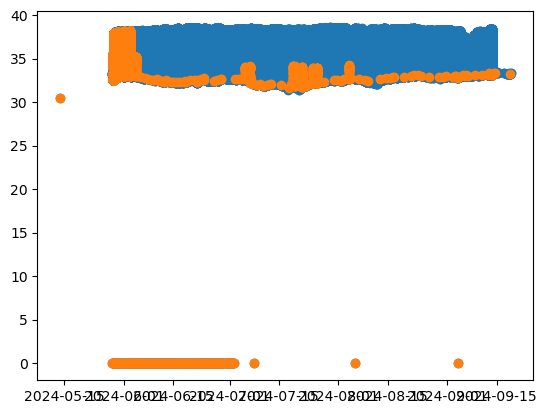

In [304]:
plt.scatter(ds.TIME, ds.DPHASE_DOXY)
plt.scatter(ds.TIME.where(~ds.TEMP.isnull()), ds.DPHASE_DOXY.where(~ds.TEMP.isnull())); 

***
# Hydrostatic pressure correction on UNCAL_PHASE [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- UNCAL_PHASE, i.e., uncalibrated phase, saved as `optode_pipeline_settings.uncal_phase`
- Pressure from the CTD, which has been adjusted for geometric lag
- Pressure correction coefficient, which depends on the optode type
</div>

Pressure can affect the optode's measured output in various ways. It affects the luminescence lifetime of the luminophores, quenching, and membrane O2 equilibrium level (Bittig et al., 2015a; Bittig et al., 2016). The effect on luminescence needs to be corrected on the <font color=pink> uncalibrated phase shift </font>, following Bittig et al. (2015a): 

$$UNCAL\_PHASE\_Pcorr = UNCAL\_PHASE + Pcoef1 \frac{1}{1000} * PRES_{geoshift}$$

$UNCAL\_PHASE_\_Pcorr$ = Hydrostatic pressure corrected DPHASE

$Pcoef1$ = Phase offset depending on the sensing foil and manufacturer, e.g., 0.1 deg per 1000 dbar for Aanderaa optodes. 

$PRES_{geoshift}$ = Pressure geometrically aligned to optode 

Note that the pressure used in this correction is the one that has been geometrically adjusted for the different locations of the optode and CTD on the glider. 

The pressure effect on quencing and on membrane O2 equilibrium level will be corrected on the oxygen concentration: MOLAR_DOXY, which is done after the salinity correction. 

<div class="alert alert-block alert-warning">
<b>Warning: </b> 
    
Pressure correction needs to be applied to the uncalibrated phase shift, _not_ the calibratd phase shift. If uncalibrated phase shift is not available, skip this hydrostatic pressure correction. 
</div>

In [50]:
def phase_hydrost_press_corr(optode_pipeline_settings, UNCAL_PHASE, PRES_geoshift, Pcoef1=None): 
    """
    Correcting optode phase shift for hydrostatic pressure effect on luminescence lifetime. 
    Following best practice protocols, including Pcoef1 = 0.1 deg (Bittig et al., 2015). 

    
    ARGS:
        UNCAL_PHASE: array-like
            Uncalibrated phase measurements. Unit = deg. 
            Thierry et al. (2025a): For 3830 optodes, PHASE = UNCAL_Phase = BPhase. For 4330 optodes, PHASE = TCPhase. 
        PRES_geoshift: array-like
            Pressure measurements that have previously been adjusted for geometric alignment with the optode. Unit = dbar. 
        Pcoef1 = float 
            Pressure correction coefficient. Unit = deg. Default = 0.1. 


    RETURN: 
        UNCAL_PHASE_Pcorr: array-like
            Uncalibrated phase shift values corrected for hydrostatic pressure effect. 
        
    Sources: 
        - Bittig et al. (2015): Bittig, H.C., B. Fielder, P. Fietzk and A. Kortzinger (2015): Pressure Response 
        of Aanderaa and Sea-Bird Oxygen Optodes. J. Atmos. Oceanic Tech., 32, 2305-2317, doi: 10.1175/JTECH-D-15-0108.1
        - Bittig et al. (2018): Bittig, H.C.,. A. Körtzinger, C. Neill, E. van Ooijen, J. N. Plant, J. Hahn, 
        K. S. Johnson, B. Yang, and S. R. Emerson (2018): Oxygen Optode Sensors: Principle, Characterization, 
        Calibration and Application in the Ocean. Front. Mar. Sci., 4, 429, doi: 10.3389/fmars.2017.00429
        - Thierry et al. (2025): Thierry V., H. Bittig, D. Gilbert, T. Kobayashi, K. Sato, C. Schmid, 2025: 
        Processing Argo OXYGEN data at the DAC level, v2.3.4, http://dx.doi.org/10.13155/39795
    """

    # Pressure correction coefficient (Pcoef1) differs per sensor
    if not Pcoef1: # If Pcoef1 argument = None, apply Pcoef1 from dictionary based on sensor type
        Pcoef1 = optode_pipeline_settings.Pcoef1
        print("Hydrostatic pressure correction done with Pcoef1 = ", Pcoef1, "(", optode_pipeline_settings.sensor_type,")")
    else:
        print("Hydrostatic pressure correction done with GIVEN Pcoef1 = ", Pcoef1)

    # Apply hydrostatic pressure correction 
    UNCAL_PHASE_Pcorr = UNCAL_PHASE + (Pcoef1*P_geoshift)/1000

    return UNCAL_PHASE_Pcorr

    

<div class="alert alert-block alert-success">
STEP: Apply hydrostatic pressure correction on uncalibrated phase shift (UNCAL_PHASE): 
</div>

In [ ]:
optode_pipeline_settings.uncal_phase_pcorr = optode_pipeline_settings.uncal_phase + "_Pcorr" # set the name for the pressure corrected uncalibrated phase shift
UNCAL_PHASE = ds[optode_pipeline_settings.uncal_phase]
ds[optode_pipeline_settings.uncal_phase_pcorr] =  phase_hydrost_press_corr(optode_pipeline_settings, UNCAL_PHASE = UNCAL_PHASE, PRES_geoshift = ds.PRES, Pcoef1=None)


***
# Derive calibrated phase shift (DPHASE_DOXY) [READY]

<div class="alert alert-block alert-info">
<b>Required input: </b>

- UNCAL_PHASE, i.e., uncalibrated phase
- PhaseCoef calibration coefficients from the manufacturer
</div>



This is the temperature compensation step, converting the uncalibrated phase into a "calibrated phase". 

Note that the function is given in this section, but applied in the next when we loop through available phase shift data in the dataset. 

This step is the same for Aanderaa 3830 and 4330 <font color=orange> and 4831 </font>. 

- aa3830: Correction from BPhase_Pcorr to DPhase
- aa4330: Correction from TCPhase_Pcorr to CalPhase
- aa4831: Correction from UNCAL_PHASE_Pcorr to DPhase

$$DPHASE = CALPHASE$$

After this step, we end up with a calibrated phase shift that is called `DPHASE_DOXY`. 

In [109]:
def calculate_dphase_aa(ds, UNCAL_PHASE, cal_sheet_aa): 
    """
    Determine DPHASE (i.e., calibrated phase) using 3rd degree polynomial and UNCAL_PHASE_Pcorr. 

    ARGS:
        PhaseCoef0-3: floats (saved in cal_sheet_aa, i.e., the manufacturer calibration sheet)
            Phase shift coefficients provided by the manufacturer
        UNCAL_PHASE_Pcorr : array-like
            Uncalibrated phase shift of the optode, which has ideally been corrected for pressure. Unit = deg. 
    RETURN:
        DPHASE_DOXY data array added to dataset 
    
    """
    A = cal_sheet_aa.PhaseCoef0
    B = cal_sheet_aa.PhaseCoef1
    C = cal_sheet_aa.PhaseCoef2
    D = cal_sheet_aa.PhaseCoef3

    DPHASE_DOXY = A + (B*UNCAL_PHASE_Pcorr) + (C*UNCAL_PHASE_Pcorr**2) + (D*UNCAL_PHASE_Pcorr**3)

    return DPHASE_DOXY
    

<div class="alert alert-block alert-success">
STEP: Calculate calibrated phase (DPHASE) from uncalibrated phase, which has ideally been corrected for pressure (UNCAL_PHASE_Pcorr): 
</div>

In [ ]:
optode_pipeline_settings.cal_phase = "DPHASE_DOXY" # name the calibrated phase shift
UNCAL_PHASE_Pcorr = ds[optode_pipeline_settings.uncal_phase_Pcorr] # determine the calibrated phase shift

ds[optode_pipeline_settings.cal_phase] = UNCAL_PHASE_Pcorr

***
# Response lag correction to phase [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- ... 
</div>

In [ ]:
from scipy.interpolate import interp1d
from scipy.signal import medfilt

## Hahn2014

In [ ]:
def response_lag_corr_hahn2014(time, phase, temperature, tau_DO):
    """
    Apply an optode response lag correction to optode phase data according to Hahn 2014. 
    This code is based on gt_sg_sensors_aa4330 from UEA_Seaglider_Toolbox. 
    Note: Safest to use optode temperature rather than CTD temperature to avoid geometric lag effects
    between optode and CTD. 
    This lag correction is designed for a "standard" optode foil. Do not apply this lag correction 
    for a fast optode. 

    ARGS:
        time : array-like
            Time array [days or datetime64], same length as tphase.
        tphase : array-like
            Measured optode phase values. 
        temperature : array-like
            Optode temperature in °C (used for temperature-dependent tau). 
        tau_DO : tuple or list
            Two coefficients [tau0, tau1] for sensor lag (s) as per Hahn correction:
            tau = tau0 + tau1 * (T - 20)
    
    RETURN: 
        tphase_corrected : ndarray
            Lag-corrected phase values, same length as input.

    Sources: 
        Hahn 2014
    """

    # Convert time to seconds relative to start
    time_s = (time - time[0]) * 24 * 60 * 60  # assuming 'time' in days
    time_s = np.asarray(time_s)

    # Compute temperature-dependent tau (Hahn 2014)
    tau = tau_DO[0] + tau_DO[1] * (temperature - 20)

    # Define high-resolution (1 Hz) time grid
    time_hr = np.arange(time_s[0], time_s[-1], 5)  # 5 s spacing (~0.2 Hz)
    
    # Optional simple filtering (replace with e.g. medfilt if desired)
    def smooth(x, kernel_size=3):
        return medfilt(x, kernel_size=kernel_size)

    # Interpolate to high-resolution grid
    phase_hr = np.interp(time_hr, time_s, smooth(phase))
    tau_hr = np.interp(time_hr, time_s, smooth(tau))

    # Preallocate corrected phase array
    phase_new = np.copy(phase_hr)

    # Apply stepwise lag correction (recursive form)
    for j in range(1, len(phase_hr)):
        dt = time_hr[j] - time_hr[j - 1]
        exp_factor = np.exp(-dt / tau_hr[j - 1])
        numerator = phase_hr[j] - phase_hr[j - 1] * exp_factor
        denominator = 1 - exp_factor
        phase_new[j] = numerator / denominator

    # Downsample back to original timestamps
    interp_func = interp1d(time_hr, phase_new, bounds_error=False, fill_value="extrapolate")
    phase_corrected = interp_func(time_s)

    dict_idata["PHASE_lagcorr"] = phase_corrected


***
# Phase shift to DO concentration (MOLAR_DOXY) [READY]

Convert DPHASE_DOXY_Pcorr (i.e. calibrated phase with first pressure correction) to MOLAR_DOXY (in umol L-1). 

This requires another set of foil0dependant coefficients and a 4th degree polynomial (provided by manufacturer). 

<font color=orange> Using DPHASE as input here and temporarily ignoring PHASE_lagcorr because latter will be developed later and am still unsure where it sits in the pipeline (20251111). </font> 

## Aanderaa 3930, 3835, 3975, 4130, and 4175 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- DPHASE_DOXY_Pcorr, i.e., pressure corrected calibrated phase
- Set of foil-dependant calibration coefficients from the manufacturer
</div>

### DPHASE to MOLAR_DOXY [READY]

In [ ]:
def dphase_to_molar_doxy_aa38(DPHASE_DOXY, T, cal_sheet_aa): 
    """
    Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater). 
    This function applies to Aanderaa optodes 3930, 3835, 3975, 4130, and 4175 only. 
    Use temperature from ... <CHECK AND COMPLETE>
    
    ARGS: 
        T : float or array-like
            Temperature in degC. CHECK WHICH TEMPERATURE
        FoilCalCoef : float
            20 foil-dependant calibration coefficient. Each set is associated to each batch of foils. Provide by manufacturer. 

    RETURN: 
        MOLAR_DOXY : dissolved oxygen concentration in umol L-1 for salinity = 0
    """

    C0 = cal_sheet_aa.FoilCalCoef0 + cal_sheet_aa.FoilCalCoef1*T  + cal_sheet_aa.FoilCalCoef2*T**2 + cal_sheet_aa.FoilCalCoef3*T**3
    C1 = cal_sheet_aa.FoilCalCoef4 + cal_sheet_aa.FoilCalCoef5*T  + cal_sheet_aa.FoilCalCoef6*T**2 + cal_sheet_aa.FoilCalCoef7*T**3
    C2 = cal_sheet_aa.FoilCalCoef8 + cal_sheet_aa.FoilCalCoef9*T  + cal_sheet_aa.FoilCalCoef10*T**2 + cal_sheet_aa.FoilCalCoef11*T**3
    C3 = cal_sheet_aa.FoilCalCoef12 + cal_sheet_aa.FoilCalCoef13*T  + cal_sheet_aa.FoilCalCoef14*T**2 + cal_sheet_aa.FoilCalCoef15*T**3
    C4 = cal_sheet_aa.FoilCalCoef16 + cal_sheet_aa.FoilCalCoef17*T  + cal_sheet_aa.FoilCalCoef18*T**2 + cal_sheet_aa.FoilCalCoef19*T**3

    MOLAR_DOXY = C0 + C1*DPHASE_DOXY + C2*DPHASE_DOXY**2 + C3*DPHASE_DOXY**3 + C4*DPHASE_DOXY**4

    return MOLAR_DOXY

<div class="alert alert-block alert-success">
STEP: Convert phase shift (DPHASE corrected for pressure) to oxygen concentration (MOLAR_DOXY): 
</div>

In [ ]:
# For Aanderaa 3930, 3835, 3975, 4130, and 4175
ds["MOLAR_DOXY"] = dphase_to_molar_doxy_aa38(DPHASE_DOXY = ds[optode_pipeline_settings.cal_phase], T = ds.TEMP, cal_sheet_aa)


## Aanderaa 4330, 4831, 4835 [READY]

<div class="alert alert-block alert-info">
<b>Required input:</b>
    
- DPHASE_DOXY, i.e., calibrated phase
- Set of foil-dependant calibration coefficients from the manufacturer
- Temperature - CHECK WHICH ONE
- Salinity
</div>

For Aanderaa 4330, 4831, and 4835, the phase shift is converted into a molar concentration of oxygen (i.e., MOLAR_DOXY in umol L-1) in either of 2 ways, depending on whether the SVUFoilCoefs have been made available by the manufacturer. 

<b>If the SVUFoilCoefs are available</b>, apply the Stern/Volmer/Uchida formula: 

$$MOLAR\_DOXY = \frac{\frac{P_0}{P_c}-1}{K_{SV}}$$

, where 

$$K_{SV} = c_0 + c_1 * T + c_2 * T^2$$ 

$$P_0 = C_3 + C_4 * T $$

$$P_c = c_5 + c_6 * DPHASE\_DOXY\_Pcorr$$

, and T is temperature in degC. <font color=orange> Check which temperature: from CTD or from optode! </font> 

<b>If the SVUFoilCoefs are unavailable </b>, MOLAR_DOXY is calculated from the oxygen solubility (cm3 / dm3; determined from Garcia & Gordon, 1992) and from percentage air saturation: 

$$C^\ast = exp [A_0 + A_1 * T_S + A_2 * T_S^2 + A_3 * T_S^3 + A_4 * T_S^4 + A_5 * T_S^5 + S * (B_0 + B_1 * T_S + B_2 * B_S^2 + B_3 * T_S^3) + C_0 * S^2]$$

, where 

$A_0$ - $A_5$ and $B_0$ - $B_3$ and $C_0$ are constants from Garvia & Gordon (1992), S is salinity, and $T_S$ is scaled temperature: 

$$T_S = ln(\frac{298.15 - t}{273.15 - t})$$

, where t is temperature in degC. <font color=orange> Check which temperature: from CTD or from optode! </font> 

### Oxygen solubility [READY]

In [ ]:
def oxygen_solubility_garcia_gordon_1992(T, S = 35):
    """
    Calculate oxygen solubility C* (cm³/dm³) using Garcia & Gordon (1992).
    
    ARGS: 
        T : float or array
            Temperature in °C
        S : float
            Salinity (default = 35)

    RETURNS:
        C_star : float or array
            Oxygen solubility in cm³/dm³
    """

    # Garcia & Gordon (1992) coefficients
    A0 = 2.00856
    A1 = 3.22400
    A2 = 3.99063
    A3 = 4.80299
    A4 = 9.78188e-1
    A5 = 1.71069

    B0 = -6.24097e-3
    B1 = -6.93498e-3
    B2 = -6.90358e-3
    B3 = -4.29155e-3

    C0 = -3.11680e-7

    # Scaled temperature
    Ts = np.log((298.15 - T) / (273.15 - T))

    # Main Garcia & Gordon exponential term
    C_star = np.exp(
        A0
        + A1 * Ts
        + A2 * Ts**2
        + A3 * Ts**3
        + A4 * Ts**4
        + A5 * Ts**5
        + S * (B0 + B1 * Ts + B2 * Ts**2 + B3 * Ts**3)
        + C0 * S**2
    )

    return C_star

### Vapour pressure [READY]

In [ ]:
def calculate_vapour_pressure(T):
    """
    Calculate water vapour pressure (hPa) from temperature (°C), following ... 

    ARGS: 
        T : float or array-like
            Temperature in degC (CHECK IF FROM OPTODE OR CTD)
    """
    return np.exp(52.57 - (6690.0 / (T + 273.15)) - 4.681 * np.log(T + 273.15))



### Oxygen partial pressure [READY]

In [ ]:
def calculate_delta_p(DPHASE_DOXY, T, C, m, n): 
    """
    Calculate partial pressure of oxygen (Δp) from DPHASE_DOXY_Pcorr, temperature, and polynomial calibration coefficients, specific for the foil given by the manufacturer. 
    
    Δp = Σ C[i] * t^m[i] * dphase^n[i]

    ARGS:
        DPHASE_DOXY : float or array
            Calibrated phase shift (DPHASE_DOXY) from the optode corrected for pressure
        T : float or array : CONFIRM WHICH TEMPERATURE
            Temperature (°C)
        C : list or array of coefficients C0 ... C27
        m : list or array of polynomial degrees for temperature
        n : list or array of polynomial degrees for dphase

    RETURNS
        Δp : float or array
            Partial pressure of oxygen in hPa. 
    """
    
    C = np.asarray(C)
    m = np.asarray(m)
    n = np.asarray(n)

    terms = C * (T ** m) * (DPHASE_DOXY ** n)
    
    return np.sum(terms)

### Air saturation [READY]

In [ ]:
def calculate_air_saturation(delta_p, p_vapour):
    """
    Calculate the air saturation (%), following ... 

    ARGS: 
        delta_p : float or array-like
            Partial pressure of oxygen in hPa
        p_vapour : float or array-like
            Water vapour pressure in hPa

    RETURNS:
        AirSaturation: float or array-like
            Air saturation percentage. 
    """

    NomAirPress = 1013.25 # nominal air pressure, hPa
    NomAirMix = 0.20946 # nominal oxygen content in air, hPa
    
    AirSaturation = (delta_p * 100) / ((NomAirPress - p_vapour) * NomAirMix)

    return AirSaturation

### DPHASE to MOLAR_DOXY [READY]

In [15]:
def dphase_to_molar_doxy_aa43(DPHASE_DOXY, T, S, cal_sheet_aa, method = None): 
    """
    Calculate dissolved oxygen concentration in umol L-1 from calibrated phase, for salinity = 0 (i.e., freshwater). 
    This function applies to Aanderaa optodes 4330, 4831, and 4835 only. 
    Use temperature from ... <CHECK AND COMPLETE>

    ARGS : 
        T: float or array-like
            Temperature in degC. CHECK WHICH TEMPERATURE. 
        S: float or array-like
            Practical salinity from CTD geometrically aligned with the optode. 
        Manufacturer calibration sheet: 
        method : string either, "SVU" or "poly"
            "SVU" signifies that the SVU method will be applied to calculate molar concentration of oxygen. 
            This is only possible of SVUFoilCoef0-6 are available in the manufacturer calibration sheet. 
            "poly" signifies that the molar oxygen concentration for oxygen will be calculated using oxygen solubility and air saturation. 
            The latter depends on the partial pressure of oxygen, which requires 27 polynomial coefficients from the manufacturer. 

    RETURN: 
        MOLAR_DOXY: Oxygen concentration in umol L-1 for salinity = 0. 
    
    """

    
    if method == "SVU": # If SVU foil coefficients are available
        c0 = cal_sheet_aa.SVUFoilCoef0
        c1 = cal_sheet_aa.SVUFoilCoef1
        c2 = cal_sheet_aa.SVUFoilCoef2
        c3 = cal_sheet_aa.SVUFoilCoef3
        c4 = cal_sheet_aa.SVUFoilCoef4
        c5 = cal_sheet_aa.SVUFoilCoef5
        c6 = cal_sheet_aa.SVUFoilCoef6
        
        K_SV = c0 + c1*T + c2*T**2
        P0 = c3 + c4*T
        Pc = c5 + c6*DPHASE_DOXY # Use pressure corrected DPHASE
        
        MOLAR_DOXY = ((P0 / Pc) - 1) / K_SV


    elif method == "poly": # If SVU foil coefficients are not available 

        # Read in all foil coefficients
        c0 = cal_sheet_aa.FoilCoefA0
        c1 = cal_sheet_aa.FoilCoefA1
        c2 = cal_sheet_aa.FoilCoefA2
        c3 = cal_sheet_aa.FoilCoefA3
        c4 = cal_sheet_aa.FoilCoefA4
        c5 = cal_sheet_aa.FoilCoefA5
        c6 = cal_sheet_aa.FoilCoefA6
        c7 = cal_sheet_aa.FoilCoefA7
        c8 = cal_sheet_aa.FoilCoefA8
        c9 = cal_sheet_aa.FoilCoefA9
        c10 = cal_sheet_aa.FoilCoefA10
        c11 = cal_sheet_aa.FoilCoefA11
        c12 = cal_sheet_aa.FoilCoefA12
        c13 = cal_sheet_aa.FoilCoefA13
        c14 = cal_sheet_aa.FoilCoefB0
        c15 = cal_sheet_aa.FoilCoefB1
        c16 = cal_sheet_aa.FoilCoefB2
        c17 = cal_sheet_aa.FoilCoefB3
        c18 = cal_sheet_aa.FoilCoefB4
        c19 = cal_sheet_aa.FoilCoefB5
        c20 = cal_sheet_aa.FoilCoefB6
        c21 = cal_sheet_aa.FoilCoefB7
        c22 = cal_sheet_aa.FoilCoefB8
        c23 = cal_sheet_aa.FoilCoefB9
        c24 = cal_sheet_aa.FoilCoefB10
        c25 = cal_sheet_aa.FoilCoefB11
        c26 = cal_sheet_aa.FoilCoefB12
        c27 = cal_sheet_aa.FoilCoefB13

        # Read in all polynomial degrees for temperature
        m0 = cal_sheet_aa.FoilPolyDegT0
        m1 = cal_sheet_aa.FoilPolyDegT1
        m2 = cal_sheet_aa.FoilPolyDegT2
        m3 = cal_sheet_aa.FoilPolyDegT3
        m4 = cal_sheet_aa.FoilPolyDegT4
        m5 = cal_sheet_aa.FoilPolyDegT5
        m6 = cal_sheet_aa.FoilPolyDegT6
        m7 = cal_sheet_aa.FoilPolyDegT7
        m8 = cal_sheet_aa.FoilPolyDegT8
        m9 = cal_sheet_aa.FoilPolyDegT9
        m10 = cal_sheet_aa.FoilPolyDegT10
        m11 = cal_sheet_aa.FoilPolyDegT11
        m12 = cal_sheet_aa.FoilPolyDegT12
        m13 = cal_sheet_aa.FoilPolyDegT13
        m14 = cal_sheet_aa.FoilPolyDegT14
        m15 = cal_sheet_aa.FoilPolyDegT15
        m16 = cal_sheet_aa.FoilPolyDegT16
        m17 = cal_sheet_aa.FoilPolyDegT17
        m18 = cal_sheet_aa.FoilPolyDegT18
        m19 = cal_sheet_aa.FoilPolyDegT19
        m20 = cal_sheet_aa.FoilPolyDegT20
        m21 = cal_sheet_aa.FoilPolyDegT21
        m22 = cal_sheet_aa.FoilPolyDegT22
        m23 = cal_sheet_aa.FoilPolyDegT23
        m24 = cal_sheet_aa.FoilPolyDegT24
        m25 = cal_sheet_aa.FoilPolyDegT25
        m26 = cal_sheet_aa.FoilPolyDegT26
        m27 = cal_sheet_aa.FoilPolyDegT27

        # Read in all polynomial degrees for oxygen
        n0 = cal_sheet_aa.FoilPolyDegO0
        n1 = cal_sheet_aa.FoilPolyDegO1
        n2 = cal_sheet_aa.FoilPolyDegO2
        n3 = cal_sheet_aa.FoilPolyDegO3
        n4 = cal_sheet_aa.FoilPolyDegO4
        n5 = cal_sheet_aa.FoilPolyDegO5
        n6 = cal_sheet_aa.FoilPolyDegO6
        n7 = cal_sheet_aa.FoilPolyDegO7
        n8 = cal_sheet_aa.FoilPolyDegO8
        n9 = cal_sheet_aa.FoilPolyDegO9
        n10 = cal_sheet_aa.FoilPolyDegO10
        n11 = cal_sheet_aa.FoilPolyDegO11
        n12 = cal_sheet_aa.FoilPolyDegO12
        n13 = cal_sheet_aa.FoilPolyDegO13
        n14 = cal_sheet_aa.FoilPolyDegO14
        n15 = cal_sheet_aa.FoilPolyDegO15
        n16 = cal_sheet_aa.FoilPolyDegO16
        n17 = cal_sheet_aa.FoilPolyDegO17
        n18 = cal_sheet_aa.FoilPolyDegO18
        n19 = cal_sheet_aa.FoilPolyDegO19
        n20 = cal_sheet_aa.FoilPolyDegO20
        n21 = cal_sheet_aa.FoilPolyDegO21
        n22 = cal_sheet_aa.FoilPolyDegO22
        n23 = cal_sheet_aa.FoilPolyDegO23
        n24 = cal_sheet_aa.FoilPolyDegO24
        n25 = cal_sheet_aa.FoilPolyDegO25
        n26 = cal_sheet_aa.FoilPolyDegO26
        n27 = cal_sheet_aa.FoilPolyDegO27

        # Put all coefficients and polynomial degrees into lists
        C = [c0, c1, c2, c3, c4, c5, c6, c7, c8, c9, c10, c11, c13, c14, 
            c15, c16, c17, c18, c19, c20, c21, c22, c23, c24, c25, c26, c27]
        m = [m0, m1, m2, m3, m4, m5, m6, m7, m8, m9, m10, m11, m13, m14, 
            m15, m16, m17, m18, m19, m20, m21, m22, m23, m24, m25, m26, m27]
        n = [n0, cn, n2, n3, n4, n5, n6, n7, n8, n9, n10, n11, n13, n14, 
            n15, n16, n17, n18, n19, n20, n21, n22, n23, n24, n25, n26, n27]
        
        C_star = oxygen_solubility_garcia_gordon_1992(T = T, S = S) # oxygen solubility (cm3/dm3), calculated from Garcia & Gordon (1992)
        
        delta_p = calculate_delta_p(DPHASE_DOXY = DPHASE_DOXY, T = T, C = C, m = m, n = n) # calculate the partial pressure of oxygen (hPa)
        p_vapour = calculate_vapour_pressure(T) # calculate water vapour pressure (hPa)
        AirSaturation = calculate_air_saturation(delta_p, p_vapour) # calculate air saturation (%)
        
        MOLAR_DOXY_UNCOR = (C_star * 44.659 * AirSaturation) / 100 # calculate molar oxygen concentration for salinity = 0, not yet corrected with final calibration

        MOLAR_DOXY = MOLAR_DOXY_UNCOR * cal_sheet_aa.ConcCoef1 + cal_sheet_aa.ConcCoef0 # Calculate corrected molar oxygen concentration for salinity = 0
        
        
    else: 
        print("The 'method' argument must be either 'SVU' or 'poly'. MOLAR_DOXY not calculated. ")
        MOLAR_DOXY = None

SyntaxError: invalid syntax (935267528.py, line 102)

<div class="alert alert-block alert-success">
STEP: Convert phase shift (DPHASE corrected for pressure) to oxygen concentration (MOLAR_DOXY): 
</div>

In [ ]:
# For Aanderaa 4330, 4831, 4835
S = ds.PRAC_SALINITY
T = ds.TEMP # CHECK
DPHASE_DOXY = ds[optode_pipeline_settings.cal_phase]

ds["MOLAR_DOXY"] = dphase_to_molar_doxy_aa38(DPHASE_DOXY = DPHASE_DOXY, T = T, S = S, cal_sheet_aa)



***
# Salinity correction [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input: </b>
    
- ...
- 
</div>

## Partial pressure of water vapour [READY]

In [ ]:
def ph2o_weiss_price_1980(S, T): 
    """ 
    Calculate the partial pressure of water vapour, following Weiss & Price (1980). 
    Range 273 to 313K and 0--40% salinity
    Standard error of 0.015% of pH2O, an average of about 5 × 10 -6 atm 
    over this range (Weiss&Price, 1980)

    ARGS: 
        S : float or array-like 
            Salinity (practical)
        T : float or array-like
            Temperature (degC). 

    RETURNS: 
        ph2o : float or array-like
            Partial pressure of water vapour (mbar). 

    CITATION: 
        Weiss, R. F., & Price, B. A. (1980). Nitrous oxide solubility in water 
    and seawater. Marine chemistry, 8(4), 347-359.
    """

    T = T+273.15 # Convert degrees C to Kelvin
    
    # Constants from polynomial equation 10 in Weiss&Price, 1980.
    A = 24.4543
    B = -67.4509
    C = -4.8489
    D = -0.000544
    
    # Equation 10 in Weiss&Price, 1980
    ph2o = 1013.25 * np.exp(A + B*(100/T) + C*np.log(T/100) + D*S)
    
    return ph2o


## SCorr [READY]

In [ ]:
def oxygen_solubility_salinity_correction(S, T, Spreset=0):
    """
    Compute the salinity correction factor SCorr from Garcia & Gordon (1992), using the Benson & Krause refit.
    Also see Bittig et al. (2016). 

    ARGS: 
        S : float or array
            Actual salinity.
        T : float or array
            Temperature in °C.
        Spreset : float, optional
            Reference salinity (e.g., 0 for freshwater or 35 for preset seawater).

    RETURNS: 
        SCorr : float or array
            SCorr salinity correction factor.
    """

    # Coefficients (Garcia & Gordon 1992 – Benson & Krause refit)
    B0 = -6.24523e-3
    B1 = -7.37614e-3
    B2 = -1.03410e-2
    B3 = -8.17083e-3
    C0 = -4.88682e-7

    # Scaled temperature term Ts
    Ts = np.log((298.15 - T) / (273.15 + T))

    # SCorr computation
    SCorr = np.exp(
        (S - Spreset) * (B0 + B1*Ts + B2*(Ts**2) + B3*(Ts**3))
        + C0 * ((S**2) - (Spreset**2))
    )

    return SCorr

In [ ]:
def salinity_correction(MOLAR_DOXY, T, S, Spreset = 0): 
    """
    Apply salinity correction to molar oxygen concentrations according to Bittig et al. (2016). 

    ARGS: 
        MOLAR_DOXY: float or array-like
            Molar oxygen concentration calculated for salinity = 0 (umol L-1)
        T : float or array-like
            Temperature (degC)
        S : float or array-like
            Actual salinity 
        Spreset : float, optional
            Reference salinity (e.g., 0 for freshwater or 35 for preset seawater).

    RETURNS: 
        MOLAR_DOXY_PSAL : float or array-like
            Molar oxygen concentration corrected for actual salinity (umol L-1)
    
    """

    # Calculate factor with partial pressure of water vapour, following Weiss & PRice (1980)
    A = 1013.25 - ph2o_weiss_price_1980(S = Spreset, T = T) # 1 mbar = 1hPa 
    B = 1013.25 - ph2o_weiss_price_1980(S = S, T = T # 1 mbar = 1hPa 

    S_Corr = oxygen_solubility_salinity_correction(S = S, T = T, Spreset=0)

    MOLAR_DOXY_PSAL = (A/B) * S_Corr * MOLAR_DOXY

    return MOLAR_DOXY_PSAL

    

<div class="alert alert-block alert-success">
STEP: Apply salinity correction: 
</div>

In [ ]:
T = ds.TEMP
S = ds.PRAC_SALINITY
MOLAR_DOXY = ds["MOLAR_DOXY"]
ds["MOLAR_DOXY_PSAL"] = salinity_correction(MOLAR_DOXY, T, S, Spreset = 0)


***
# DPHASE to pO2

Bittig et al. (2016) suggest that the salinity correction can be skipped when accounting for the O2-T response using a different mathematical model that determines the oxygen output in terms of partial pressure (pO2) instead of molar concentration (MOLAR_DOXY) (Uchida et al., 2010). pO2 is independent of salinity, and thus a salinity correction is not applicable. pO2 can then be converted to MOLAR_DOXY, using the SCOR WG 132 recommendations for convertions. 

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will implement the possibility of this step at a later stage. 
</div>

***
# Hydrostatic pressure correction [IN PROGRESS]

<div class="alert alert-block alert-info">
<b>Required input: </b>

- MOLAR_DOXY_PSAL, i.e., salinity-corrected oxygen concentration (umol L-1)
- Pressure from CTD that has been corrected for geometric lag (dbar)
</div>

Correct for hydrostatic pressure correction on quenching and membrane O2 equilibrium. 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

Incorporate Argo: Thierry et al., 2025a p 28-29. 
</div>



In [ ]:
def DO_hydrost_press_corr_aa(MOLAR_DOXY_PSAL, PRES):
    """
    Correct for hydrostatic pressure effect on quenching and membrane O2 equilibrium for Aanderaa optodes. 

    ARGS:
        MOLAR_DOXY_PSAL: array-like
            Salinity-corrected oxygen concentration. Unit = umol L-1. 
        PRES: array-like
            Pressure adjusted for geometric lag. Unit = dbar. 

    RETURNS: 
        MOLAR_DOXY_PSAL_PRES : array-like
            Pressure corrected oxygen concentration (umol L-1). 

    Sources:
        - Bittig et al. (2015): Bittig, H.C., B. Fielder, P. Fietzk and A. Kortzinger (2015): 
        Pressure Response of Aanderaa and Sea-Bird Oxygen Optodes. J. Atmos. Oceanic Tech., 
        32, 2305-2317, doi: 10.1175/JTECH-D-15-0108.1
        
    """
    
    MOLAR_DOXY_PSAL_PRES = MOLAR_DOXY_PSAL *(1.0 + ((0.032 * PRES) / 1000.0))

    return MOLAR_DOXY_PSAL_PRES


    

<div class="alert alert-block alert-success">
STEP: Apply second pressure correction: 
</div>

In [ ]:
MOLAR_DOXY_PSAL = ds.MOLAR_DOXY_PSAL
PRES = ds.PRES
ds["MOLAR_DOXY_PSAL_PRES"] = DO_hydrost_press_corr_aa(MOLAR_DOXY_PSAL, PRES)

***
# MOLAR_DOXY to DOXY [IN PROGRESS]

Convert MOLAR_DOXY (umol L-1) to DOXY (umol kg-1), following SCOR WG 142 recommendations. 

In [ ]:
def calculate_potential_density(T, S): 
    """
    
    """


    return rho

In [ ]:
def o2_umolL_to_umolkg(MOLAR_DOXY, T, S):
    """
    Convert oxygen from µmol/L to µmol/kg using potential density of seawater (kg L-1) referenced to a hydrostatic pressure of 0 dbar and using practical salinity.

    Bittig et al. (2016) recommends using equation of state based on Fofonoff and Millard (1983) and Millero et al. (1980). 
    
    
    ARGS: 
        MOLAR_DOXY : array or float
            Oxygen concentration in µmol/L
        T : array or float
            Temperature (°C)
        S : array or float
            Practical salinity (psu)
    
    RETURNS: 
        DOXY : array or float
            Oxygen concentration in µmol/kg
    """
    rho_kgm3 = density_unesco(S, T)     # kg/m^3
    rho_kgl = rho_kgm3 / 1000.0         # convert to kg/L

    DOXY = MOLAR_DOXY / rho_kgl

    return DOXY

<div class="alert alert-block alert-success">
STEP: Convert MOLAR_DOXY to DOXY: 
</div>

In [ ]:
ds["DOXY"] = o2_umolL_to_umolkg(MOLAR_DOXY = ds.MOLAR_DOXY, T = ds.TEMP, S = ds.PRAC_SALINITY)


***
# Tests

<font color=pink> These tests need to be done on oxygen in umol kg-1. </font> 

## Global range check

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>


In [ ]:
def global_range_check(DOXY, TEMP_DOXY):
    """
    Apply global range checks for DOXY and TEMP_DOXY.
    
    ARGS: 
        DOXY : float or array-like
            Oxygen concentration (µmol kg-1).
        TEMP_DOXY : float or array-like
            Optode temperature (°C).

    RETURNS: 
        qc_doxy : ndarray
            QC flags for DOXY (1 = good, 4 = bad).
        qc_temp : ndarray
            QC flags for TEMP_DOXY (1 = good, 4 = bad).
    """

    doxy = np.asarray(doxy, dtype=float)
    temp_doxy = np.asarray(temp_doxy, dtype=float)

    # Initialize QC flags with "1" (good)
    qc_doxy = np.ones_like(doxy, dtype=int)
    qc_temp = np.ones_like(temp_doxy, dtype=int)

    # Apply global range checks
    qc_doxy[(doxy < -5) | (doxy > 600)] = 4
    qc_temp[(temp_doxy < -2.5) | (temp_doxy > 40)] = 4

    return qc_doxy, qc_temp

## Regional range check

> add explanation

<div class="alert alert-block alert-warning">
Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

## Outlier and spike check

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

## Gradient test

> add explanation

<div class="alert alert-block alert-warning">
Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

## Digit roll over test

> add explanation

<div class="alert alert-block alert-warning">
Check with Dan whether regional range check can be implemented on general level. Not sure it's relevant for other variable pipelines.  
</div>

## Stuck value test

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

## Frozen profile test

## Bad P/T/S QC spreading

> add explanation


<div class="alert alert-block alert-warning">
<b>Already in toolbox </b> 

See test in standard_pipeline.yams. 
</div>

***
# Storage drift correction: 2-point calibrations

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- This might have to be done on phase level or given the option to do at phase or at conc level.
- Check with IMOS and Argo

</div>

***
# Unit conversions

Unit conversions follow the recommendations by the SCOR Working Group 142. 

<div class="alert alert-block alert-warning">
<b>To do: </b> 

- Convert SCOR WG 142 matlab code to python 

</div>

***
# Validation with ship CTD casts

<div class="alert alert-block alert-warning">
<b>Low priority</b> 

Will be done at a later stage and might even have to appear in a different part of the pipeline. 
</div>

:)